# Imports

In [6]:
#none of the imports are in the environment so far
import pandas as pd
import numpy as np
import mne
import matplotlib.pyplot as plt
# data path might be connected to the example data that the tutorials want me to load, but since it seems to be used as a function below I am not sure if I might still need it  
from mne.datasets.eyelink import data_path
from mne.io import read_raw_eyelink
import seaborn as sns
import os

#where do I have the following line from, doesnt work so do I need it?
#from mne.preprocessing.eyetracking import read_eyelink_calibration

In [7]:
print(mne.__version__)
# print(dir(mne))
help(mne.io)

1.5.1
Help on package mne.io in mne:

NAME
    mne.io - IO module for reading raw data.

PACKAGE CONTENTS
    _digitization
    _read_raw
    array (package)
    artemis123 (package)
    base
    besa (package)
    boxy (package)
    brainvision (package)
    bti (package)
    cnt (package)
    compensator
    constants
    ctf (package)
    ctf_comp
    curry (package)
    diff
    edf (package)
    eeglab (package)
    egi (package)
    eximia (package)
    eyelink (package)
    fieldtrip (package)
    fiff (package)
    fil (package)
    hitachi (package)
    kit (package)
    matrix
    meas_info
    nedf (package)
    nicolet (package)
    nihon (package)
    nirx (package)
    nsx (package)
    open
    persyst (package)
    pick
    proc_history
    proj
    reference
    snirf (package)
    tag
    tests (package)
    tree
    utils
    what
    write

FILE
    /mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/lib/python3.10/site-packages/mne/io/__init__.py




In [8]:
## ask or for function that loads the data and cleans the ram at the same time


# data_dir = "/mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/data_eyelink_limited_copy"


# data_files = os.listdir(data_dir)

# print(data_files)

# data_list = []

# for data_file in data_files:
#     if data_file.endswith(".asc") and "pr.asc" not in data_file:
#         # Load the data using MNE-Python

#         # maybe I should just remove the preload=True so it is not loaded into memory: "By loading only the header information with preload=False, 
#         # MNE-Python minimizes memory usage and allows you to inspect the basic characteristics of the data without loading the potentially large data samples."
#         # -- does not seem to make a difference?
#         raw = mne.io.read_raw_eyelink(os.path.join(data_dir, data_file),  preload=False)
#         # raw = mne.io.read_raw_eyelink(os.path.join(data_dir, data_file), preload=True)
        
        
#         # Extract the subject ID from the filename (assuming a certain naming convention)
#         subject_id = os.path.splitext(data_file)[0]
        
#         # Create a Pandas Series with the subject ID as a column
#         data_dict = {"SubjectID": subject_id}
        
#         # Convert the MNE Raw object to a Pandas DataFrame
#         df = raw.to_data_frame()
#         memory_df = df.memory_usage(index=True).sum()
#         print(memory_df)
#         # Append the subject ID column to the DataFrame
#         df = df.assign(**data_dict)
        
#         # Append the DataFrame to the data list
#         data_list.append(df)


# final_df = pd.concat(data_list, ignore_index=True)




In [9]:
## try to find frequency hz and potentially change


In [10]:
# this works but might not be what I want. Definitely missing the subID

folder_path = "/mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/data_eyelink"

et_fpath = folder_path + "/REUNMA.asc"

raw_et = mne.io.read_raw_eyelink(et_fpath, preload=True, create_annotations=["blinks"])


# no idea what the following line is supposed to do, probably is supposed to add individual data files to the general path, could probably be done better, might want to loop over the files in the folder like I did in the behav_data, BUT concatenating them might not be a good idea,
# even though I might have to concatenate them to be able to calculate means, but no I dont think I need that for the means, maybe though...

Loading /mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/data_eyelink/REUNMA.asc
Pixel coordinate data detected.Pass `scalings=dict(eyegaze=1e3)` when using plot method to make traces more legible.
Pupil-size area detected.


In [11]:
# the degbug crashes the whole computer
# wanted to try to load the data in debug mode to check why it sometimes just stops loading midway without giving me an error message

# with mne.use_log_level("debug"):
#     raw_et = mne.io.read_raw_eyelink(et_fpath)

mne.sys_info()

Platform             Linux-5.4.0-94-generic-x86_64-with-glibc2.31
Python               3.10.12 | packaged by conda-forge | (main, Jun 23 2023, 22:40:32) [GCC 12.3.0]
Executable           /mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/bin/python
CPU                  x86_64 (32 cores)
Memory               125.8 GB

Core
├☑ mne               1.5.1
├☑ numpy             1.25.1 (unknown linalg bindings (threadpoolctl module not found: No module named 'threadpoolctl'))
├☑ scipy             1.11.2
├☑ matplotlib        3.7.2 (backend=module://matplotlib_inline.backend_inline)
├☑ pooch             1.7.0
└☑ jinja2            3.1.2

Numerical (optional)
├☑ pandas            2.0.3
└☐ unavailable       sklearn, numba, nibabel, nilearn, dipy, openmeeg, cupy

Visualization (optional)
└☐ unavailable       pyvista, pyvistaqt, vtk, qtpy, ipympl, pyqtgraph, mne-qt-browser, ipywidgets, trame_client, trame_server, trame_vtk, trame_vuetify

Ecosystem (optional)
└☐ unavailable       mne-bids, mne-ni

In [12]:

annotations = raw_et.annotations
print(annotations)

# Print the first few annotations and their descriptions
for idx, desc in enumerate(annotations.description[:20]):
    print(f"Annotation {idx + 1}: {desc}")

<Annotations | 3319 segments, channel-specific: BAD_blink (3319)>
Annotation 1: BAD_blink
Annotation 2: BAD_blink
Annotation 3: BAD_blink
Annotation 4: BAD_blink
Annotation 5: BAD_blink
Annotation 6: BAD_blink
Annotation 7: BAD_blink
Annotation 8: BAD_blink
Annotation 9: BAD_blink
Annotation 10: BAD_blink
Annotation 11: BAD_blink
Annotation 12: BAD_blink
Annotation 13: BAD_blink
Annotation 14: BAD_blink
Annotation 15: BAD_blink
Annotation 16: BAD_blink
Annotation 17: BAD_blink
Annotation 18: BAD_blink
Annotation 19: BAD_blink
Annotation 20: BAD_blink


## Info

In [22]:

info = raw_et.info
print(raw_et.info)
info_keys = info.keys()
print("These are the info keys:", info_keys)
ch_names = info["ch_names"]
print(ch_names)
print(info["chs"][0].keys())
# print(info["chs"]["loc"])

# Assuming you have an `info` object already defined
for channel_info in info['chs']:
    kind = channel_info['kind']
    print(f"Kind of channel: {kind}")

# just shows me the integer that corresponds to that channel name (in the 6th position)
print(mne.pick_channels(info["ch_names"], include=["DIN"]))
# the same but rückwärts
print(mne.channel_type(info, 6))

# channels by type
ch_idx_by_type = mne.channel_indices_by_type(info)
print(ch_idx_by_type.keys())
print(ch_idx_by_type["eyegaze"])

<Info | 7 non-empty values
 bads: []
 ch_names: xpos_left, ypos_left, pupil_left, xpos_right, ypos_right, ...
 chs: 4 Eye-tracking (Gaze position), 2 Eye-tracking (Pupil size), 1 Stimulus, 3 misc
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: 2023-04-20 03:55:10 UTC
 nchan: 10
 projs: []
 sfreq: 500.0 Hz
>
These are the info keys: dict_keys(['acq_pars', 'acq_stim', 'ctf_head_t', 'description', 'dev_ctf_t', 'dig', 'experimenter', 'utc_offset', 'device_info', 'file_id', 'highpass', 'hpi_subsystem', 'kit_system_id', 'helium_info', 'line_freq', 'lowpass', 'meas_date', 'meas_id', 'proj_id', 'proj_name', 'subject_info', 'xplotter_layout', 'gantry_angle', 'bads', 'chs', 'comps', 'events', 'hpi_meas', 'hpi_results', 'projs', 'proc_history', 'custom_ref_applied', 'sfreq', 'dev_head_t', 'ch_names', 'nchan'])
['xpos_left', 'ypos_left', 'pupil_left', 'xpos_right', 'ypos_right', 'pupil_right', 'DIN', 'x_head', 'y_head', 'distance']
dict_keys(['loc', 'unit_mul', 'range',

In [15]:
# sample_data_raw_file = (
#     sample_data_folder / "MEG" / "sample" / "sample_audvis_filt-0-40_raw.fif"
# )

## would have liked to only load the info of individual data files. I wanted to then put this in a loop and look at all the sfreq frequencies to check if they were the same for the different participants, does not seem to work though


# info_for_all = mne.io.read_info(et_fpath)
# print(info_for_all)

In [23]:
raw2 = raw_et.get_data()


# I think the same can work for epochs if I have them
# epoch_np = epochs_et.get_data()

# Both Raw and Epochs objects have get_data methods that return the underlying data as a NumPy array. Both methods have a picks parameter for subselecting which channel(s) to return; raw.get_data() has additional parameters for restricting the time domain. The resulting matrices have dimension (n_channels, n_times) for Raw and (n_epochs, n_channels, n_times) for Epochs.

## from MNE Python Tutorial
probably useful then to use a numpy library like tried below

event_dict = {

    "auditory/left": 1,
    "auditory/right": 2,
    "visual/left": 3,
    "visual/right": 4,
    "smiley": 5,
    "buttonpress": 32,
}

Event dictionaries like this one are used when extracting epochs from continuous data; the / character in the dictionary keys allows pooling across conditions by requesting partial condition descriptors (i.e., requesting 'auditory' will select all epochs with Event IDs 1 and 2; requesting 'left' will select all epochs with Event IDs 1 and 3).


## trying to find the triggers (events and/or annotations)

In [24]:
# events = mne.find_events(raw_et, initial_event=True, consecutive='increasing')
# I am assuming that DIN must be the stimulus channel, what else would it be?
events = mne.find_events(raw_et, stim_channel="DIN", initial_event=True)

# the following just makes a list of regularly spaced intervals of the data.. 
events2 = mne.make_fixed_length_events(raw_et)

# the following line returns an empty array
print("This is events:", events)

# this returns an array but there is one column with indexes, one column just with zeros and one column with only ones
print("This is events:", events2)


# fig = mne.viz.plot_events(
#     events, sfreq=raw_et.info["sfreq"], first_samp=raw_et.first_samp
# )

This is events: []
This is events: [[      0       0       1]
 [    500       0       1]
 [   1000       0       1]
 ...
 [3222000       0       1]
 [3222500       0       1]
 [3223000       0       1]]


## Annotations

In [25]:
# this seems to return something.. maybe there are not MEG/EEG type events but rather annotations

# however "BAS_blink" seems to be the only annotation found
print("another try", raw_et.annotations)

print(len(raw_et.annotations))
print(set(raw_et.annotations.duration))
print(set(raw_et.annotations.description))
print(raw_et.annotations.onset[0])

# events_from_annot, event_dict  = mne.events_from_annotations(raw_et)
# print(event_dict)
# print(events_from_annot[:5])


# custom_mapping = {"BAD_blink": 77}
# (events_from_annot, event_dict) = mne.events_from_annotations(
#     raw_et, event_id=custom_mapping
# )
# print(event_dict)
# print(events_from_annot[:5])

another try <Annotations | 3319 segments, channel-specific: BAD_blink (3319)>
3319
{0.25, 0.242, 0.5, 3.622, 4.28, 5.658, 0.734, 0.726, 8.104, 1.104, 2.848, 2.144, 12.94, 5.568, 5.96, 10.18, 10.22, 19.382, 22.296, 24.766, 25.998, 26.94, 27.028, 27.524, 27.598, 26.546, 0.75, 39.674, 39.298, 39.544, 49.886, 50.018, 0.796, 54.188, 1.796, 0.218, 0.226, 0.234, 0.476, 0.21, 1.976, 1.476, 1.726, 78.006, 78.052, 81.96, 82.338, 1.406, 86.224, 0.374, 1.342, 111.788, 1.272, 120.888, 0.428, 0.178, 0.436, 0.186, 0.202, 0.444, 0.194, 0.452, 0.468, 155.488, 3.318, 1.998, 0.162, 0.154, 0.146, 0.17, 198.946, 198.184, 1.428, 2.678, 0.794, 1.794, 0.88, 0.356, 0.67, 0.396, 0.404, 0.13, 0.372, 0.122, 0.138, 0.824, 2.404, 3.154, 1.34, 284.274, 0.106, 0.114, 0.27, 0.52, 0.098, 0.09, 0.348, 0.074, 0.082, 0.246, 1.176, 0.292, 0.332, 0.066, 0.284, 0.324, 0.308, 1.362, 0.316, 2.862, 0.058, 0.05, 1.972, 0.042, 0.62, 0.034, 0.026, 3.582, 0.268, 0.768, 0.018, 0.01, 1.878, 0.846, 0.346, 0.002, 0.542, 1.51, 0.518, 1.

In [ ]:
## need to know which channel has my events?
# something like: events = mne.find_events(raw_et, stim_channel="STI 101")

In [26]:
# i think this shows me wether any configuration variables were set (which there arent apparently) --> 
#This is normal if you haven't explicitly configured any custom settings. 
print(mne.get_config()) 

# all the keys that MNE-Python recognizes and uses, regardless of whether they’ve been set on your system
print(mne.get_config(key=""))

# path for the configuration
print(mne.get_config_path())

print(mne.get_config("MNE_LOGGING_LEVEL"))

{}
{'MNE_3D_OPTION_ANTIALIAS': 'bool, whether to use full-screen antialiasing in 3D plots', 'MNE_3D_OPTION_DEPTH_PEELING': 'bool, whether to use depth peeling in 3D plots', 'MNE_3D_OPTION_MULTI_SAMPLES': 'int, number of samples to use for full-screen antialiasing', 'MNE_3D_OPTION_SMOOTH_SHADING': 'bool, whether to use smooth shading in 3D plots', 'MNE_3D_OPTION_THEME': 'str, the color theme (light or dark) to use for 3D plots', 'MNE_BROWSE_RAW_SIZE': 'tuple, width and height of the raw browser window (in inches)', 'MNE_BROWSER_BACKEND': 'str, the backend to use for the MNE Browse Raw window (qt or matplotlib)', 'MNE_BROWSER_OVERVIEW_MODE': 'str, the overview mode to use in the MNE Browse Raw window )(see mne.viz.plot_raw for valid options)', 'MNE_BROWSER_PRECOMPUTE': 'bool, whether to precompute raw data in the MNE Browse Raw window', 'MNE_BROWSER_THEME': 'str, the color theme (light or dark) to use for the browser', 'MNE_BROWSER_USE_OPENGL': 'bool, whether to use OpenGL for rendering 

In [27]:
print(mne.get_config("missing_config_key", default="fallback value"))

fallback value


In [ ]:

# # Create empty lists to store the extracted data
# xpos_left = raw_et["xpos_left"]
# ypos_left = raw_et["ypos_left"]
# xpos_right = raw_et["xpos_right"]
# ypos_right = raw_et["ypos_right"]
# blink = raw_et["xpos_left"]

# # Create empty lists to store the extracted data
# xpos_left = []
# ypos_left = []
# xpos_right = []
# ypos_right = []
# blink = []

# # Parse the data and extract it into lists
# for line in raw_et:
#     values = line.strip().split(', ')
#     xpos_left.append(int(values[0]))
#     ypos_left.append(int(values[1]))
#     xpos_right.append(int(values[2]))
#     ypos_right.append(int(values[3]))
#     blink.append(bool(values[4].lower() == 'true'))

# # Create a DataFrame from the extracted data
# eye_tracking_data = pd.DataFrame({
#     'x_left': xpos_left,
#     'y_left': ypos_left,
#     'x_right': xpos_right,
#     'y_right': ypos_right,
#     'blink': blink
# })


In [28]:
## Could potentially change the sequencing/epoching, right now it is probably default, right now there seems to be a timestamp ever 2ms (0.002 seconds) - if it indeed is in seconds

# Can add the rest of the data to this manually (maybe there is a better way though)


print(ch_names)


# why is this line not commented out?:
Output: ['xpos_left', 'ypos_left', 'pupil_left', 'xpos_right', 'ypos_right', 'pupil_right', 'DIN', 'x_head', 'y_head', 'distance']

xpos_left = raw_et["xpos_left"]
ypos_left = raw_et["ypos_left"]
xpos_right = raw_et["xpos_right"]
ypos_right = raw_et["ypos_right"]
pupil_left = raw_et['pupil_left']
pupil_right = raw_et['pupil_right']

# Extract data and timestamps separately
timestamps = xpos_left[1]
xpos_left_data = xpos_left[0][0]
ypos_left_data = ypos_left[0][0]
xpos_right_data = xpos_right[0][0]
ypos_right_data = ypos_right[0][0]
pupil_left_data = pupil_left[0][0]
pupil_right_data = pupil_right[0][0]

# Create a pandas DataFrame with column name 'xpos_left' and data and timestamps as values
eyetracking_data = pd.DataFrame({'timestamps': timestamps, 'xpos_left': xpos_left_data,'ypos_left': ypos_left_data, 'xpos_right': xpos_right_data, 'ypos_right': ypos_right_data, 'pupil_left': pupil_left_data, 'pupil_right': pupil_right_data})

print(raw_et['pupil_left'])


['xpos_left', 'ypos_left', 'pupil_left', 'xpos_right', 'ypos_right', 'pupil_right', 'DIN', 'x_head', 'y_head', 'distance']
(array([[ 810.,  810.,  810., ..., 1062., 1066., 1065.]]), array([0.000000e+00, 2.000000e-03, 4.000000e-03, ..., 6.447670e+03,
       6.447672e+03, 6.447674e+03]))


## Heatmaps

In [29]:
# plt.figure(figsize=(8,6))
# sns.set_context('paper', font_scale=1.4)
data = pd.DataFrame({'score':[10,11,12,13], 'score2':[7,2,22,63]})
# datadf = (data)
print(data)
data_mx = data.corr()
print(data_mx)

sns.heatmap(eyetracking_data, mask=0.5)

   score  score2
0     10       7
1     11       2
2     12      22
3     13      63
           score    score2
score   1.000000  0.877127
score2  0.877127  1.000000


TypeError: Cannot perform 'ror_' with a dtyped [bool] array and scalar of type [bool]

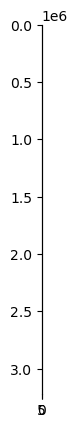

In [30]:
fig, ax = plt.subplots()
im = ax.imshow(eyetracking_data)

NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Using matplotlib as 2D backend.


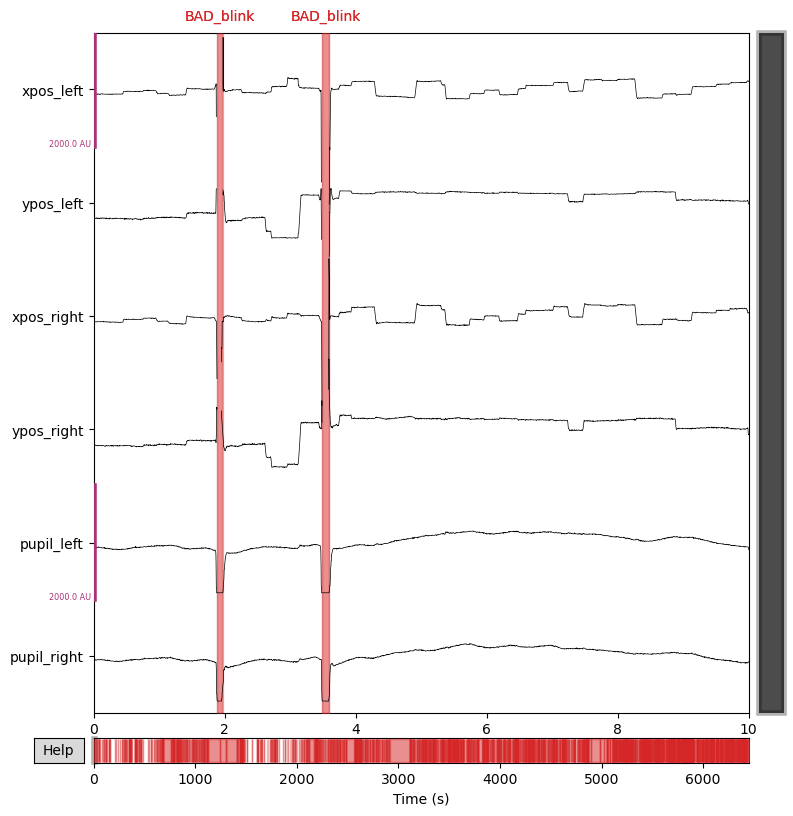

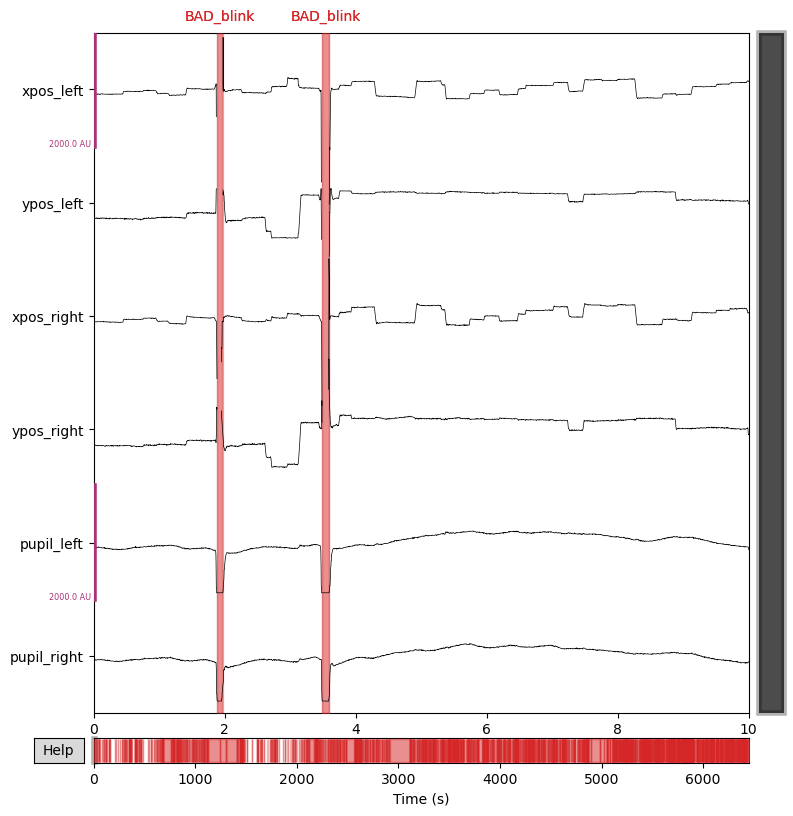

In [31]:
## Plots

# why are only two frames shown, what is the timing, what is the scaline, what is eyegaze=1e3

custom_scalings = dict(eyegaze=1e3)
raw_et.pick_types(eyetrack=True).plot(scalings=custom_scalings)

In [ ]:
## Need the general x,y coordinates (with NANs for blinks)
